In [2]:
import pandas as pd

In [ ]:
df_indiv = pd.read_csv("data/contributions_individuals.csv", dtype=str)
df_contrib = pd.read_csv("data/contributions_organization.csv", dtype=str)


In [10]:
print(len(df_indiv))
print(len(df_contrib))

158838
335


In [7]:
# Count empty/missing values per column
print("\nMissing values per column in indiv datase:")
print(df_indiv.isna().sum() + (df_indiv.eq('').sum())) #  # counts both NaN and empty strings



Missing values per column in indiv datase:
contributor_name                     0
contributor_first_name              58
contributor_last_name               58
contributor_street_1                 0
contributor_street_2            134638
contributor_city                     0
contributor_state                    0
contributor_zip                      0
contributor_employer             76602
contributor_occupation           76356
committee_id                         0
committee_name                  158838
contribution_receipt_date            0
contribution_receipt_amount          0
contribution_aggregate_ytd      158838
is_refunded_or_reattributed     158838
contribution_refunded_amount    158838
sub_id                               0
transaction_id                       0
two_year_transaction_period          0
lat                                  0
lng                                  0
geocode_provider                     5
geocode_checked_at                   1
contributor_year    

In [ ]:
# ----------------------------- 
print("\nMissing values in org dataset per column:")
print(df_contrib.isna().sum() + (df_contrib.eq('').sum())) #  # counts both NaN and empty strings


Missing values in org dataset per column:
contributor_name                  0
contributor_first_name          331
contributor_last_name           335
contributor_street_1              0
contributor_street_2            243
contributor_city                  0
contributor_state                 0
contributor_zip                   0
contributor_employer            331
contributor_occupation          331
committee_id                      0
committee_name                  335
contribution_receipt_date         0
contribution_receipt_amount       0
contribution_aggregate_ytd      335
is_refunded_or_reattributed     335
contribution_refunded_amount    335
sub_id                            0
transaction_id                    0
two_year_transaction_period       0
lat                               0
lng                               0
geocode_provider                  0
geocode_checked_at                0
contributor_year                  0
zip5                              0
dtype: int64


## Dropping

In [ ]:
cols_to_drop = [
    'committee_name',
    'contribution_aggregate_ytd',
    'is_refunded_or_reattributed',
    'contribution_refunded_amount',
    'geocode_provider',
    'geocode_checked_at'
]

df_indiv = df_indiv.drop(columns=cols_to_drop)

# Rename column
df_indiv = df_indiv.rename(columns={'two_year_transaction_period': 'year_cycle'})

# Verify changes
print(df_indiv.columns)



cols_to_drop = [
    'committee_name',
    'contribution_aggregate_ytd',
    'is_refunded_or_reattributed',
    'contribution_refunded_amount',
    'geocode_provider',
    'geocode_checked_at'
]

df_contrib = df_contrib.drop(columns=cols_to_drop)

# Rename column
df_contrib = df_contrib.rename(columns={'two_year_transaction_period': 'year_cycle'})

# Verify changes
print(len(df_contrib.columns))



Index(['contributor_name', 'contributor_first_name', 'contributor_last_name',
       'contributor_street_1', 'contributor_street_2', 'contributor_city',
       'contributor_state', 'contributor_zip', 'contributor_employer',
       'contributor_occupation', 'committee_id', 'contribution_receipt_date',
       'contribution_receipt_amount', 'sub_id', 'transaction_id', 'year_cycle',
       'lat', 'lng', 'contributor_year'],
      dtype='object')
Index(['contributor_name', 'contributor_first_name', 'contributor_last_name',
       'contributor_street_1', 'contributor_street_2', 'contributor_city',
       'contributor_state', 'contributor_zip', 'contributor_employer',
       'contributor_occupation', 'committee_id', 'contribution_receipt_date',
       'contribution_receipt_amount', 'sub_id', 'transaction_id', 'year_cycle',
       'lat', 'lng', 'contributor_year', 'zip5'],
      dtype='object')


In [ ]:
print(len(df_contrib.columns))
print(len(df_indiv.columns))

19
19


## Amount Fix Column

In [16]:
# Convert contribution_receipt_amount to numeric
df_indiv['contribution_receipt_amount'] = pd.to_numeric(df_indiv['contribution_receipt_amount'], errors='coerce')

# Drop rows where contribution_receipt_amount is <= 0 or NaN
df_indiv = df_indiv[df_indiv['contribution_receipt_amount'] > 0].copy()

print(df_indiv['contribution_receipt_amount'].describe())


# Convert contribution_receipt_amount to numeric
df_contrib['contribution_receipt_amount'] = pd.to_numeric(df_contrib['contribution_receipt_amount'], errors='coerce')

# Drop rows where contribution_receipt_amount is <= 0 or NaN
df_contrib = df_contrib[df_contrib['contribution_receipt_amount'] > 0].copy()

print(df_contrib['contribution_receipt_amount'].describe())


count    158527.000000
mean        563.158453
std        1138.871690
min           0.050000
25%          25.000000
50%         100.000000
75%         500.000000
max       51700.000000
Name: contribution_receipt_amount, dtype: float64
count      331.000000
mean      1957.892417
std       2348.071290
min          0.250000
25%        500.000000
50%       1000.000000
75%       2500.000000
max      24794.260000
Name: contribution_receipt_amount, dtype: float64


In [20]:
print("Number of rows after dropping contributors with amounts less than 0, It was 158838 = ", len(df_indiv))
print("Number of rows after dropping contributors with amounts less than 0, It was 335 = ", len(df_contrib))


Number of rows after dropping contributors with amounts less than 0, It was 158838 =  158527
Number of rows after dropping contributors with amounts less than 0, It was 335 =  331


## ZipCodes Normalization

In [21]:
zip_lengths = df_indiv['contributor_zip'].dropna().astype(str).apply(len).value_counts().sort_index()
print("Unique lengths of ZIP codes and their counts:")
print(zip_lengths)


Unique lengths of ZIP codes and their counts:
contributor_zip
5    76805
9    81722
Name: count, dtype: int64


In [23]:
zip_lengths_org= df_contrib['contributor_zip'].dropna().astype(str).apply(len).value_counts().sort_index()
print("Unique lengths of ZIP codes and their counts:")
print(zip_lengths_org)


Unique lengths of ZIP codes and their counts:
contributor_zip
5     75
9    256
Name: count, dtype: int64


In [24]:
df_indiv['contributor_zip'] = df_indiv['contributor_zip'].astype(str)

# Normalize: keep first 5 digits
df_indiv['contributor_zip'] = df_indiv['contributor_zip'].str[:5]

# Verify
print(df_indiv['contributor_zip'].head(10))
print(df_indiv['contributor_zip'].apply(len).value_counts())


0    60645
1    60645
2    33401
3    11215
4    68139
5    68139
6    68139
7    68139
8    68139
9    68139
Name: contributor_zip, dtype: object
contributor_zip
5    158527
Name: count, dtype: int64


In [25]:
df_contrib['contributor_zip'] = df_contrib['contributor_zip'].astype(str)

# Normalize: keep first 5 digits
df_contrib['contributor_zip'] = df_contrib['contributor_zip'].str[:5]

# Verify
print(df_contrib['contributor_zip'].head(10))
print(df_contrib['contributor_zip'].apply(len).value_counts())

0    85020
1    20003
2    20002
3    85020
4    20006
5    20002
6    85020
7    10123
8    21282
9    21282
Name: contributor_zip, dtype: object
contributor_zip
5    331
Name: count, dtype: int64


In [27]:
df_indiv.info()

<class 'pandas.core.frame.DataFrame'>
Index: 158527 entries, 0 to 158837
Data columns (total 19 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   contributor_name             158527 non-null  object 
 1   contributor_first_name       158479 non-null  object 
 2   contributor_last_name        158479 non-null  object 
 3   contributor_street_1         158527 non-null  object 
 4   contributor_street_2         24161 non-null   object 
 5   contributor_city             158527 non-null  object 
 6   contributor_state            158527 non-null  object 
 7   contributor_zip              158527 non-null  object 
 8   contributor_employer         82236 non-null   object 
 9   contributor_occupation       82482 non-null   object 
 10  committee_id                 158527 non-null  object 
 11  contribution_receipt_date    158527 non-null  object 
 12  contribution_receipt_amount  158527 non-null  float64
 13  sub_

## dates checking 

In [31]:
df_indiv['contribution_receipt_date'] = pd.to_datetime(df_indiv['contribution_receipt_date'], errors='coerce')
print(df_indiv['contribution_receipt_date'].describe())


df_contrib['contribution_receipt_date'] = pd.to_datetime(df_contrib['contribution_receipt_date'], errors='coerce')
print(df_contrib['contribution_receipt_date'].describe())


count                           158527
mean     2023-12-04 01:31:00.531013632
min                2021-12-16 00:00:00
25%                2023-03-22 00:00:00
50%                2024-03-13 00:00:00
75%                2024-07-31 00:00:00
max                2025-06-30 00:00:00
Name: contribution_receipt_date, dtype: object
count                              331
mean     2024-01-19 22:32:59.456193280
min                2022-02-10 00:00:00
25%                2023-06-13 00:00:00
50%                2024-06-09 00:00:00
75%                2024-08-09 00:00:00
max                2025-06-25 00:00:00
Name: contribution_receipt_date, dtype: object


In [33]:
for col in ['year_cycle']:
    print(f"{col} unique values:\n", df_indiv[col].value_counts().head(20), "\n")


year_cycle unique values:
 year_cycle
2024    104644
2022     36349
2026     17534
Name: count, dtype: int64 



## Misssing DATA

In [ ]:
missing_summary = df_indiv.isna().sum() + df_indiv.eq('').sum()
print("Missing values per column:\n", missing_summary)
 ## THE MISSING  contributor_employer    contributor_occupation WILL HBE FILLED LATER USING LLM

Missing values per column:
 contributor_name                    0
contributor_first_name             48
contributor_last_name              48
contributor_street_1                0
contributor_street_2           134366
contributor_city                    0
contributor_state                   0
contributor_zip                     0
contributor_employer            76291
contributor_occupation          76045
committee_id                        0
contribution_receipt_date           0
contribution_receipt_amount         0
sub_id                              0
transaction_id                      0
year_cycle                          0
lat                                 0
lng                                 0
contributor_year                    0
dtype: int64


In [51]:
#  rows where contributor_first_name is missing or empty
missing_first_name = df_indiv[df_indiv['contributor_first_name'].isna() | (df_indiv['contributor_first_name'] == '')]

# ALWAYS CITYPAC
print(missing_first_name.head(20))


       contributor_name contributor_first_name contributor_last_name  \
140             CITYPAC                    NaN                   NaN   
1668            CITYPAC                    NaN                   NaN   
2272            CITYPAC                    NaN                   NaN   
20438           CITYPAC                    NaN                   NaN   
45869           CITYPAC                    NaN                   NaN   
49488           CITYPAC                    NaN                   NaN   
52991           CITYPAC                    NaN                   NaN   
56759           CITYPAC                    NaN                   NaN   
57708           CITYPAC                    NaN                   NaN   
60915           CITYPAC                    NaN                   NaN   
65397           CITYPAC                    NaN                   NaN   
66932           CITYPAC                    NaN                   NaN   
69265           CITYPAC                    NaN                  

In [ ]:
#  rows where contributor_first_name is missing or empty
missing_first_name_contrib = df_contrib[df_contrib['contributor_first_name'].isna() | (df_contrib['contributor_first_name'] == '')]
print("================================")
# ALWAYS emty names
print(missing_first_name_contrib.head(20))


                                     contributor_name contributor_first_name  \
0                           GRAND CANYON STATE CAUCUS                    NaN   
1                                                NRCC                    NaN   
2                                                DSCC                    NaN   
3                           GRAND CANYON STATE CAUCUS                    NaN   
4                                    AMALGAMATED BANK                    NaN   
5                                                DSCC                    NaN   
6                           GRAND CANYON STATE CAUCUS                    NaN   
7   MID MANHATTAN POLITICAL ACTION COMMITTEE (MID ...                    NaN   
8   MARYLAND ASSOCIATION FOR CONCERNED CITIZENS PO...                    NaN   
9   MARYLAND ASSOCIATION FOR CONCERNED CITIZENS PO...                    NaN   
10  SF PROPERTIES LLC FEDERAL POLITICAL ACTION COM...                    NaN   
11            SUN POLITICAL ACTION COMMI

## Duplications

In [35]:
print("Duplicate transaction_ids:", df_indiv['transaction_id'].duplicated().sum())
print("Duplicate rows:", df_indiv.duplicated().sum())

print("Duplicate transaction_ids:", df_contrib['transaction_id'].duplicated().sum())
print("Duplicate rows:", df_contrib.duplicated().sum())


Duplicate transaction_ids: 0
Duplicate rows: 0
Duplicate transaction_ids: 0
Duplicate rows: 0


## Fixing F/L missing where contributor name is known

In [ ]:
#  old contributor_name → new contributor_name
mapping = {
    "LARSON FOR CONGRESS": "LARSON FOR CONGRESS, JOHN REP.",
    "JAIME FOR CONGRESS": "JAIME FOR CONGRESS, JAIME REP.",
    "KANSANS FOR LATURNER": "KANSANS FOR LATURNER, JAKE REP.",
    "TONY CARDENAS FOR CONGRESS": "TONY CARDENAS FOR CONGRESS, TONY REP.",
    "JOHN KENNEDY FOR US": "JOHN KENNEDY FOR US, JOHN SEN.",
    "DEBBIE LESKO FOR CONGRESS": "DEBBIE LESKO FOR CONGRESS, DEBBIE REP.",
    "KAY GRANGER CAMPAIGN FUND": "KAY GRANGER CAMPAIGN FUND, KAY REP.",
    "HIMES FOR CONGRESS": "HIMES FOR CONGRESS, JIM REP.",
    "MIKE KELLY FOR CONGRESS": "MIKE KELLY FOR CONGRESS, MIKE REP. JR.",
    "GUTHRIE FOR CONGRESS": "GUTHRIE FOR CONGRESS, BRETT REP.",
    "COMER FOR CONGRESS": "COMER FOR CONGRESS, JAMES REP. JR.",
    "NRSC": "NRSC, DAN SEN.",
    "ANDY BARR FOR CONGRESS, INC.": "ANDY BARR FOR CONGRESS, INC., ANDY REP. IV",
    "WENSTRUP FOR CONGRESS": "WENSTRUP FOR CONGRESS, BRAD REP.",
    "THE GREAT TASK": "THE GREAT TASK, LIZ REP."
}

df_indiv['contributor_name'] = df_indiv['contributor_name'].replace(mapping)


In [ ]:
# mapping dict for contributor -> (first_name, last_name)
name_map = {
    "LARSON FOR CONGRESS, JOHN REP.": ("JOHN", "LARSON FOR CONGRESS"),
    "JAIME FOR CONGRESS, JAIME REP.": ("JAIME", "JAIME FOR CONGRESS"),
    "KANSANS FOR LATURNER, JAKE REP.": ("JAKE", "KANSANS FOR LATURNER"),
    "TONY CARDENAS FOR CONGRESS, TONY REP.": ("TONY", "TONY CARDENAS FOR CONGRESS"),
    "JOHN KENNEDY FOR US, JOHN SEN.": ("JOHN", "JOHN KENNEDY FOR US"),
    "DEBBIE LESKO FOR CONGRESS, DEBBIE REP.": ("DEBBIE", "DEBBIE LESKO FOR CONGRESS"),
    "KAY GRANGER CAMPAIGN FUND, KAY REP.": ("KAY", "KAY GRANGER CAMPAIGN FUND"),
    "HIMES FOR CONGRESS, JIM REP.": ("JIM", "HIMES FOR CONGRESS"),
    "MIKE KELLY FOR CONGRESS, MIKE REP. JR.": ("MIKE", "MIKE KELLY FOR CONGRESS"),
    "GUTHRIE FOR CONGRESS, BRETT REP.": ("BRETT", "GUTHRIE FOR CONGRESS"),
    "COMER FOR CONGRESS, JAMES REP. JR.": ("JAMES", "COMER FOR CONGRESS"),
    "NRSC, DAN SEN.": ("DAN", "NRSC"),
    "ANDY BARR FOR CONGRESS, INC., ANDY REP. IV": ("ANDY", "ANDY BARR FOR CONGRESS, INC."),
    "WENSTRUP FOR CONGRESS, BRAD REP.": ("BRAD", "WENSTRUP FOR CONGRESS"),
    "THE GREAT TASK, LIZ REP.": ("LIZ", "THE GREAT TASK")
}

df_indiv["contributor_first_name"] = df_indiv.apply(
    lambda row: name_map.get(row["contributor_name"], (row["contributor_first_name"], row["contributor_last_name"]))[0],
    axis=1
)

df_indiv["contributor_last_name"] = df_indiv.apply(
    lambda row: name_map.get(row["contributor_name"], (row["contributor_first_name"], row["contributor_last_name"]))[1],
    axis=1
)

## Spot extreme contributions

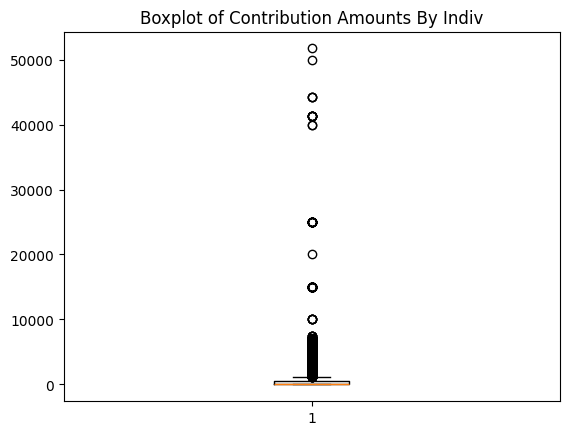

In [53]:
import matplotlib.pyplot as plt

plt.boxplot(df_indiv['contribution_receipt_amount'])
plt.title('Boxplot of Contribution Amounts By Indiv')
plt.show()


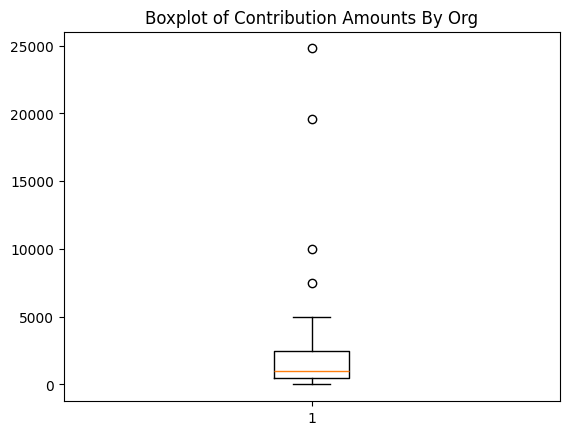

In [54]:
plt.boxplot(df_contrib['contribution_receipt_amount'])
plt.title('Boxplot of Contribution Amounts By Org')
plt.show()


## Dont Forget to save the data ;)

In [55]:
df_contrib

,contributor_name,contributor_first_name,contributor_last_name,contributor_street_1,contributor_street_2,contributor_city,contributor_state,contributor_zip,contributor_employer,contributor_occupation,committee_id,contribution_receipt_date,contribution_receipt_amount,sub_id,transaction_id,year_cycle,lat,lng,contributor_year
0,GRAND CANYON STATE CAUCUS,NaN,NaN,7108 N 20TH ST,NaN,PHOENIX,AZ,85020,NaN,NaN,C00797670,2024-02-27,1000.00,4032520241885656503,AC6E0BAA3E0314D168BB,2024,33.5405585,-112.0393149,2024
1,NRCC,NaN,NaN,320 FIRST STREET SE,.,WASHINGTON,DC,20003,NaN,NaN,C00797670,2024-11-03,300.00,4011420251130092928,AC957464A69CB40988C3,2024,38.8716043,-77.0057659,2024
2,DSCC,NaN,NaN,120 MARYLAND AVE NE,NaN,WASHINGTON,DC,20002,NaN,NaN,C00797670,2024-06-12,1000.00,4072420241978933190,ABAADD933CC624D17B6C,2024,38.8916878,-77.0049145,2024
3,GRAND CANYON STATE CAUCUS,NaN,NaN,7108 N 20TH ST,NaN,PHOENIX,AZ,85020,NaN,NaN,C00797670,2024-06-07,1000.00,4072420241978929192,A903DB8AA06FA4825A34,2024,33.5405585,-112.0393149,2024
4,AMALGAMATED BANK,NaN,NaN,1825 K ST NW,NaN,WASHINGTON,DC,20006,NaN,NaN,C00797670,2023-12-04,958.82,4020920241823947556,A0FE7E7173F1942E7952,2024,38.9027553,-77.0425231,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,HEARTLAND PAC,NaN,NaN,25330 LETCHWORTH ROAD,NaN,BEACHWOOD,OH,44122,NaN,NaN,C00797670,2022-04-25,5000.00,4122920221645228609,ABDBFD94A7E80448883A,2022,41.4717853,-81.5001073,2022
331,HEARTLAND PAC,NaN,NaN,25330 LETCHWORTH ROAD,NaN,BEACHWOOD,OH,44122,NaN,NaN,C00797670,2022-03-30,5000.00,4011420231698187046,A5FE81F2A1E7948758A7,2022,41.4717853,-81.5001073,2022
332,DSCC,NaN,NaN,120 MARYLAND AVE NE,NaN,WASHINGTON,DC,20002,NaN,NaN,C00797670,2025-05-07,1000.00,4062320251206919007,A6113E3C982464D92AA5,2026,38.8916878,-77.0049145,2025
333,GROW THE MAJORITY,NaN,NaN,228 S WASHINGTON ST STE 115,NaN,ALEXANDRIA,VA,22314,NaN,NaN,C00797670,2025-02-27,750.00,4032020251180458816,AEA44A4E1E81D46B4B42,2026,38.8005028,-77.0479401,2025


In [57]:
df_contrib.to_csv("cleanData/clean_contributionsBYcontributors.csv", index=False)
df_indiv.to_csv("cleanData/clean_contributionsBYindividuals.csv", index=False)